In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv(r"C:\Users\DELL\Downloads\airline-passengers.csv")

In [4]:
df.head(2)

,month,total_passengers
0,1949-01,112
1,1949-02,118


In [5]:
df.shape

(144, 2)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   month             144 non-null    str  
 1   total_passengers  144 non-null    int64
dtypes: int64(1), str(1)
memory usage: 3.4 KB


In [16]:
df.describe()

,total_passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000


In [10]:
df["month"]=pd.to_datetime(df["month"])
df=df.set_index("month")


In [21]:
df.head(3)

,total_passengers
month,
1949-01-01,112
1949-02-01,118
1949-03-01,132


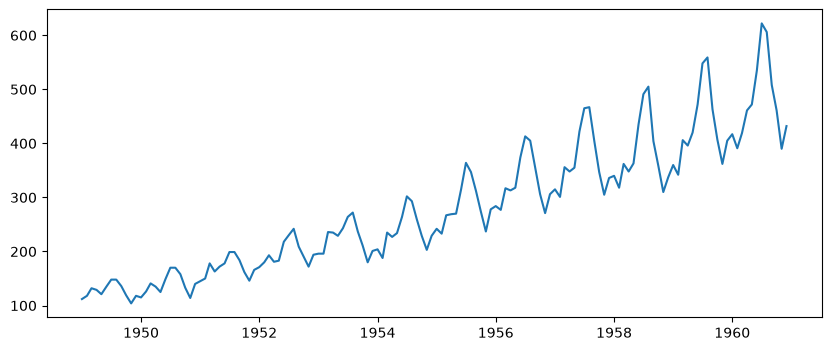

In [12]:
plt.figure(figsize=(10,4))
plt.plot(df["total_passengers"])
plt.show()


In [19]:
dates=pd.date_range(
    start="1949-01-01",
    periods=len(df),
    freq="MS"
)

In [20]:
dates

DatetimeIndex(['1949-01-01', '1949-02-01', '1949-03-01', '1949-04-01',
               '1949-05-01', '1949-06-01', '1949-07-01', '1949-08-01',
               '1949-09-01', '1949-10-01',
               ...
               '1960-03-01', '1960-04-01', '1960-05-01', '1960-06-01',
               '1960-07-01', '1960-08-01', '1960-09-01', '1960-10-01',
               '1960-11-01', '1960-12-01'],
              dtype='datetime64[us]', length=144, freq='MS')

In [29]:
ts=pd.DataFrame(
    {"passengers":df["total_passengers"]},
    index=dates
)
    

In [30]:
ts

,passengers
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
...,...
1960-08-01,606
1960-09-01,508
1960-10-01,461
1960-11-01,390


In [33]:
# !pip install statsmodels

In [34]:
ts=np.log(ts)

In [35]:
ts

,passengers
1949-01-01,4.718499
1949-02-01,4.770685
1949-03-01,4.882802
1949-04-01,4.859812
1949-05-01,4.795791
...,...
1960-08-01,6.406880
1960-09-01,6.230481
1960-10-01,6.133398
1960-11-01,5.966147


In [36]:
from statsmodels.tsa.arima.model import ARIMA

In [37]:
train=ts[:-18]
test=ts[-18:]

In [39]:
arima_model=ARIMA(train,order=(1,1,1)).fit()
        

In [40]:
arima_model

In [41]:
arima_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:             passengers   No. Observations:                  126
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 110.107
Date:                Mon, 26 Oct 2026   AIC                           -214.215
Time:                        12:53:42   BIC                           -205.730
Sample:                    01-01-1949   HQIC                          -210.768
                         - 06-01-1959                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6096      0.165     -3.691      0.000      -0.933      -0.286
ma.L1          0.8650      0.093      9.264      0.000       0.682       1.048
sigma2         0.0100      0.002      5.758      0.000       0.007       0.013
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 4.71
Prob(Q):                              0.96   Prob(JB):                         0.09
Heteroskedasticity (H):               1.02   Skew:                             0.05
Prob(H) (two-sided):                  0.95   Kurtosis:                         2.05
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [55]:
y_pred=arima_model.forecast(steps=len(test))

In [56]:
y_pred

1959-07-01    6.151789
1959-08-01    6.154953
1959-09-01    6.153024
1959-10-01    6.154200
1959-11-01    6.153483
1959-12-01    6.153920
1960-01-01    6.153653
1960-02-01    6.153816
1960-03-01    6.153717
1960-04-01    6.153777
1960-05-01    6.153740
1960-06-01    6.153763
1960-07-01    6.153749
1960-08-01    6.153757
1960-09-01    6.153752
1960-10-01    6.153755
1960-11-01    6.153754
1960-12-01    6.153755
Freq: MS, Name: predicted_mean, dtype: float64

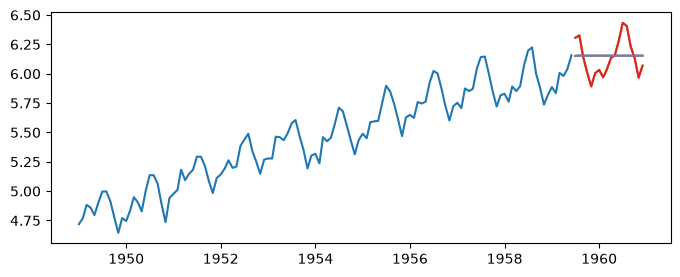

In [57]:
plt.figure(figsize=(8,3))
plt.plot(train.index,train.passengers)
plt.plot(test.index,test.passengers)
plt.plot(y_pred)
plt.plot(test)
plt.plot(y_pred)

plt.show()

NameError: name 'y_fc' is not defined

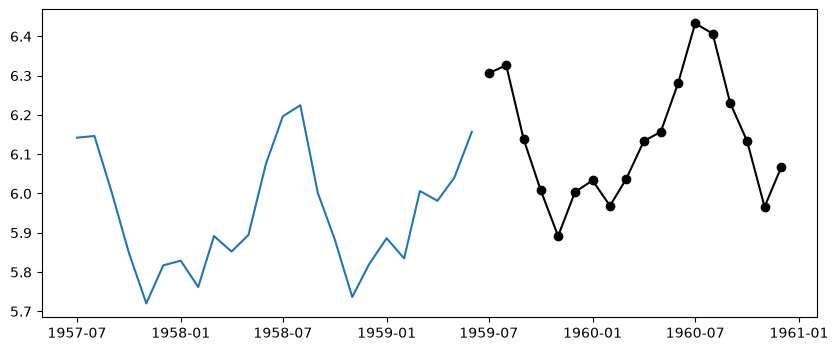

In [54]:
plt.figure(figsize=(10, 4))
plt.plot(train["passengers"][-24:], label="Train (last 2 years)")
plt.plot(test["passengers"], label="Actual (test)", color="black", marker="o")
plt.plot(y_fc, label="ARIMA forecast", linestyle="--", marker="s", color="tab:orange")
plt.legend()
plt.grid(True, alpha=0.3)
plt.title("Zoom: last 18 months")
plt.show()